<a href="https://colab.research.google.com/github/HARISHRAJ-R-07/Clustering-and-Dimensionality-Reduction/blob/main/Mall_Customer_Spending_Analysis_and_Customer_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Module - 4**

#**⌨  Assignment 08: Clustering and Dimensionality Reduction**

##**Project Title:**


> ### Mall Customer Segmentation using Unsupervised Learning

* A retail mall wants to better understand its customers based on demographics and spending behavior.Since customers are not pre-labeled into groups, the company plans to use clustering techniques to discover natural customer segments. These insights will help the marketing team design targeted campaigns, improve customer engagement, and optimize business strategies.

* In this project, you will apply clustering and dimensionality reduction techniques to identify customer groups and compare the effectiveness of different unsupervised learning approaches.

## **Task 1 – Data Exploration & Preprocessing**

> **● Load and inspect the dataset**

> **● Check shape, columns, data types, and missing values**

> **● Select relevant features for clustering**

> **● Scale numerical features appropriately**

###``` Load and inspect the dataset ```




In [1]:
# Load dataset

import numpy as np
import pandas as pd

mall_data = pd.read_excel("mall_customer_spend.xlsx")

# reference data :
original_data = mall_data
mall_data

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


###```Check shape, columns, data types, and missing values```

In [2]:
print("Shape:\n",mall_data.shape)
print("Columns:\n",mall_data.columns)
print("Datatypes:\n",mall_data.dtypes)

Shape:
 (200, 5)
Columns:
 Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')
Datatypes:
 CustomerID                 int64
Genre                     object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


In [3]:
# Identifying missing values

mall_data.isnull().sum()

,0
CustomerID,0
Genre,0
Age,0
Annual Income (k$),0
Spending Score (1-100),0


In [4]:
mall_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
# identifying is there any duplicates

mall_data.duplicated().sum()

np.int64(0)

In [6]:
# Rename columns:

mall_data.rename(columns = {"Genre" : "Gender",
                          "Annual Income (k$)" : "Annual Income",
                          "Spending Score (1-100)" : "Spending Score"}, inplace = True)
mall_data

,CustomerID,Gender,Age,Annual Income,Spending Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [7]:
# Encode the gender column with use of LabelEncooding()

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
mall_data['Gender'] = le.fit_transform(mall_data['Gender'])
print("classes in the gender column:",list(le.classes_))

classes in the gender column: ['Female', 'Male']


In [8]:
mall_data

,CustomerID,Gender,Age,Annual Income,Spending Score
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40
...,...,...,...,...,...
195,196,0,35,120,79
196,197,0,45,126,28
197,198,1,32,126,74
198,199,1,32,137,18


###```Select relevant features for clustering```

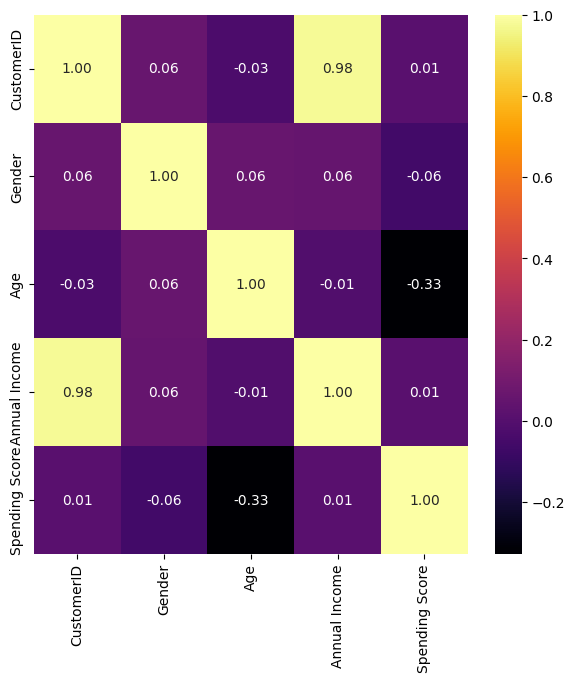

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,7))
sns.heatmap(mall_data.corr(),annot=True,fmt=".2f",cmap="inferno")
plt.show()

In [10]:
# features selected by own

feature_sel = mall_data[['Age','Annual Income','Spending Score']]
feature_sel

,Age,Annual Income,Spending Score
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40
...,...,...,...
195,35,120,79
196,45,126,28
197,32,126,74
198,32,137,18


In [11]:
feature_sel.describe()

,Age,Annual Income,Spending Score
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


###```Scale numerical features appropriately```

In [12]:
# scale the selected features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
feature_sel = scaler.fit_transform(feature_sel)

In [13]:
feature_sel = pd.DataFrame(feature_sel)
columns = ['Age',"Annual Income","Spending Score"]
feature_sel.columns = columns

In [14]:
feature_sel

,Age,Annual Income,Spending Score
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980
...,...,...,...
195,-0.276302,2.268791,1.118061
196,0.441365,2.497807,-0.861839
197,-0.491602,2.497807,0.923953
198,-0.491602,2.917671,-1.250054


In [15]:
feature_sel.describe().round(3)

,Age,Annual Income,Spending Score
count,200.000,200.000,200.000
mean,-0.000,-0.000,-0.000
std,1.003,1.003,1.003
min,-1.496,-1.739,-1.910
25%,-0.725,-0.728,-0.600
50%,-0.205,0.036,-0.008
75%,0.728,0.666,0.885
max,2.236,2.918,1.894


## **Task 2 – K-Means Clustering**

> **● Apply K-Means clustering**

> **● Demonstrate the Random Initialization Trap**

> **● Use the Elbow Method to determine the optimal number of clusters**

> **● Build the final K-Means model**










## ```Apply K-Means clustering```

## ``` Demonstrate the Random Initialization Trap```

In [16]:
# Apply K-Means clustering:

from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=5,random_state=11)

# fit the data
kmeans.fit(feature_sel)

# predict labels:
labels = kmeans.predict(feature_sel)
labels

array([3, 3, 0, 3, 3, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3,
       0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 2, 3, 0, 3,
       0, 3, 2, 3, 3, 3, 2, 3, 3, 2, 2, 2, 2, 2, 3, 2, 2, 3, 2, 2, 2, 3,
       2, 2, 3, 3, 2, 2, 2, 2, 2, 3, 2, 2, 3, 2, 2, 3, 2, 2, 3, 2, 2, 3,
       3, 2, 2, 3, 2, 2, 3, 3, 2, 3, 2, 3, 3, 2, 2, 3, 2, 3, 2, 2, 2, 2,
       2, 3, 4, 3, 3, 3, 2, 2, 2, 2, 3, 4, 1, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1, 4, 1, 4, 1, 2, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1, 4, 1,
       4, 1], dtype=int32)

In [17]:
feature_sel['labels'] = labels

In [18]:
kmeans.cluster_centers_

array([[ 0.5310735 , -1.2905084 , -1.23646671],
       [-0.42880597,  0.97484722,  1.21608539],
       [ 1.20484056, -0.23577338, -0.05236781],
       [-0.98067852, -0.74305983,  0.46744035],
       [ 0.07333084,  0.97494509, -1.19729675]])

In [19]:
import warnings
warnings.filterwarnings("ignore")

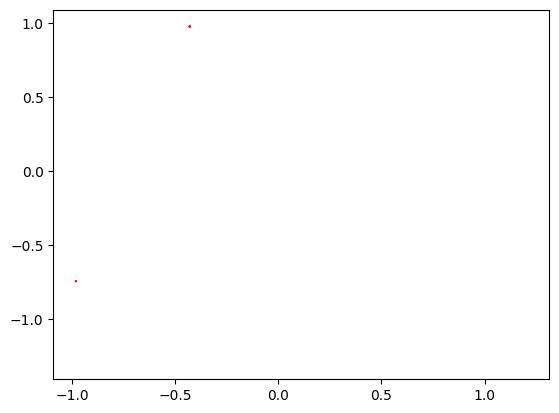

In [20]:
import plotly.express as px
feature_fig = px.scatter_3d(feature_sel, x = "Age", y = "Annual Income", z = "Spending Score",color="labels")
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:, 1], kmeans.cluster_centers_[:, 2], marker = "*", color = "red")
feature_fig.show()

## ```Use the Elbow Method to determine the optimal number of clusters```

In [21]:
# Use the Elbow Method to determine the optimal number of clusters(With-clusters sum of squares)

wcss = []

cluster = range(1,11)

for k in cluster:
  opt_k = KMeans(n_clusters=k,random_state=11)
  opt_k.fit(feature_sel)

  # append to wcss variable via inertia_ attibute

  wcss.append(opt_k.inertia_)

best_k = pd.DataFrame({"Cluster" : cluster, "WCSS" : wcss})
best_k

,Cluster,WCSS
0,1,916.480000
1,2,725.726646
2,3,519.085716
3,4,348.517769
4,5,168.247580
5,6,139.185440
6,7,123.840352
7,8,109.185444
8,9,98.360142
9,10,88.015890


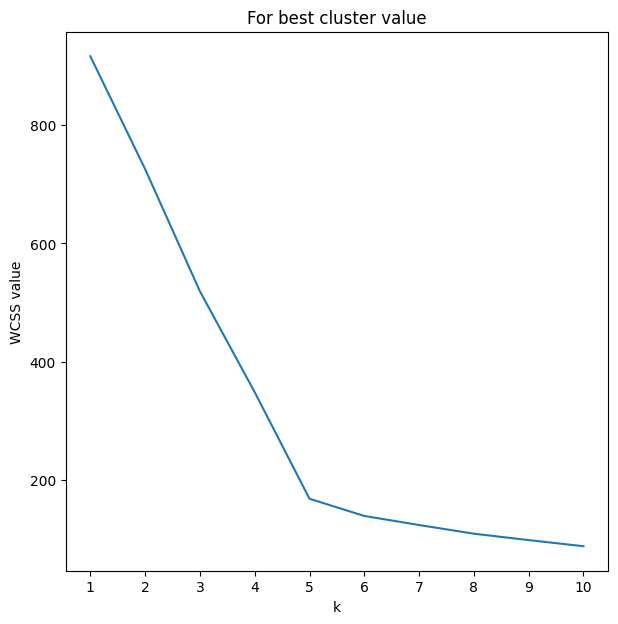

In [22]:
# Visualize the values of WCSS

plt.figure(figsize=(7,7))
plt.plot(cluster,wcss)
plt.title("For best cluster value")
plt.xlabel("k")
plt.ylabel("WCSS value")
plt.xticks(range(1,11))
plt.show()

In [23]:
# Using silhouette_score:

from sklearn.metrics import silhouette_score

sil_s =[]

clusters = range(2,11)

for k in clusters:

  opt_k_by_sil = KMeans(n_clusters=k,random_state=11)
  opt_k_by_sil.fit(feature_sel)
  pre_labels = opt_k_by_sil.predict(feature_sel)

  sil_s.append(silhouette_score(feature_sel,pre_labels))

sil_df = pd.DataFrame({'K':clusters,'Sil_scores':sil_s})
sil_df


,K,Sil_scores
0,2,0.346429
1,3,0.329968
2,4,0.435137
3,5,0.558164
4,6,0.523899
5,7,0.482369
6,8,0.463386
7,9,0.426183
8,10,0.432525


###**In this case silhouette score refer the highest point value is the best optimal clusters**

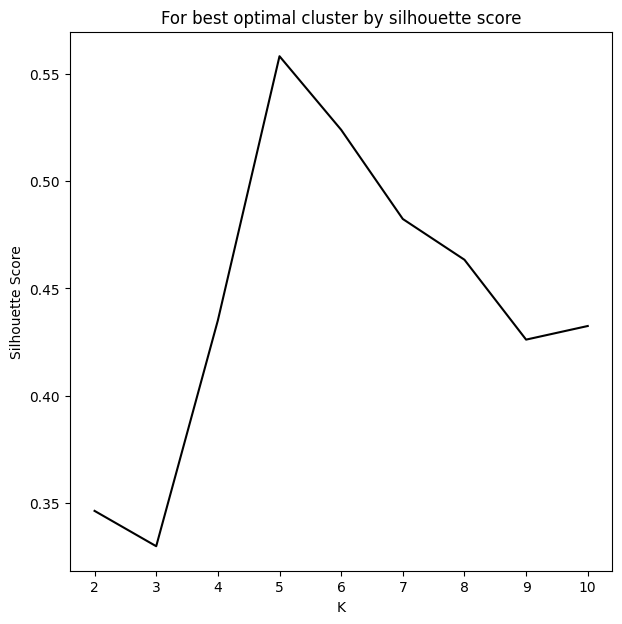

In [24]:
# Visualize the silhouette score

plt.figure(figsize=(7,7))
plt.plot(clusters,sil_s,color="black")
plt.title("For best optimal cluster by silhouette score")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.xticks(range(2,11))
plt.show()

## ```Build the final K-Means model```

In [25]:
# final kmean model:

final_kmeans = KMeans(n_clusters=5, init="k-means++", random_state=11)
final_kmeans.fit(feature_sel)


KMeans(n_clusters=5, random_state=11)

In [26]:
# predict

final_kmeans_label = final_kmeans.predict(feature_sel)

## **Task 3 – Hierarchical Clustering**

>**● Generate a Dendrogram**

>**● Apply Agglomerative Hierarchical Clustering**

>**● Compare cluster formation with K-Means**

In [27]:
# firstly import the dendogram and linkage from scipy package

from scipy.cluster.hierarchy import dendrogram, linkage



##``` Generate a Dendrogram ```



In [28]:
# Hierarchical clustering:
#     Generate a Dendrogram(using via linkage matrix)

linkage_matrix = linkage(feature_sel,method='ward')
print(f"Linkage Matrix:/n",linkage_matrix)

Linkage Matrix:/n [[6.50000000e+01 6.80000000e+01 7.17666897e-02 2.00000000e+00]
 [1.29000000e+02 1.31000000e+02 7.17666897e-02 2.00000000e+00]
 [1.06000000e+02 1.09000000e+02 7.76431214e-02 2.00000000e+00]
 [3.00000000e+00 5.00000000e+00 9.00803899e-02 2.00000000e+00]
 [1.14000000e+02 1.15000000e+02 1.05730374e-01 2.00000000e+00]
 [9.20000000e+01 9.60000000e+01 1.05730374e-01 2.00000000e+00]
 [1.33000000e+02 1.37000000e+02 1.12409152e-01 2.00000000e+00]
 [1.60000000e+01 2.00000000e+01 1.14508288e-01 2.00000000e+00]
 [6.00000000e+01 7.00000000e+01 1.20910138e-01 2.00000000e+00]
 [1.17000000e+02 1.19000000e+02 1.30409100e-01 2.00000000e+00]
 [1.50000000e+02 1.52000000e+02 1.36800877e-01 2.00000000e+00]
 [1.12000000e+02 1.21000000e+02 1.38349565e-01 2.00000000e+00]
 [4.80000000e+01 4.90000000e+01 1.43533379e-01 2.00000000e+00]
 [1.13000000e+02 2.04000000e+02 1.47460919e-01 3.00000000e+00]
 [1.00000000e+02 1.05000000e+02 1.48690768e-01 2.00000000e+00]
 [1.01000000e+02 2.05000000e+02 1.523

In [29]:
feature_sel

,Age,Annual Income,Spending Score,labels
0,-1.424569,-1.738999,-0.434801,3
1,-1.281035,-1.738999,1.195704,3
2,-1.352802,-1.700830,-1.715913,0
3,-1.137502,-1.700830,1.040418,3
4,-0.563369,-1.662660,-0.395980,3
...,...,...,...,...
195,-0.276302,2.268791,1.118061,1
196,0.441365,2.497807,-0.861839,4
197,-0.491602,2.497807,0.923953,1
198,-0.491602,2.917671,-1.250054,4


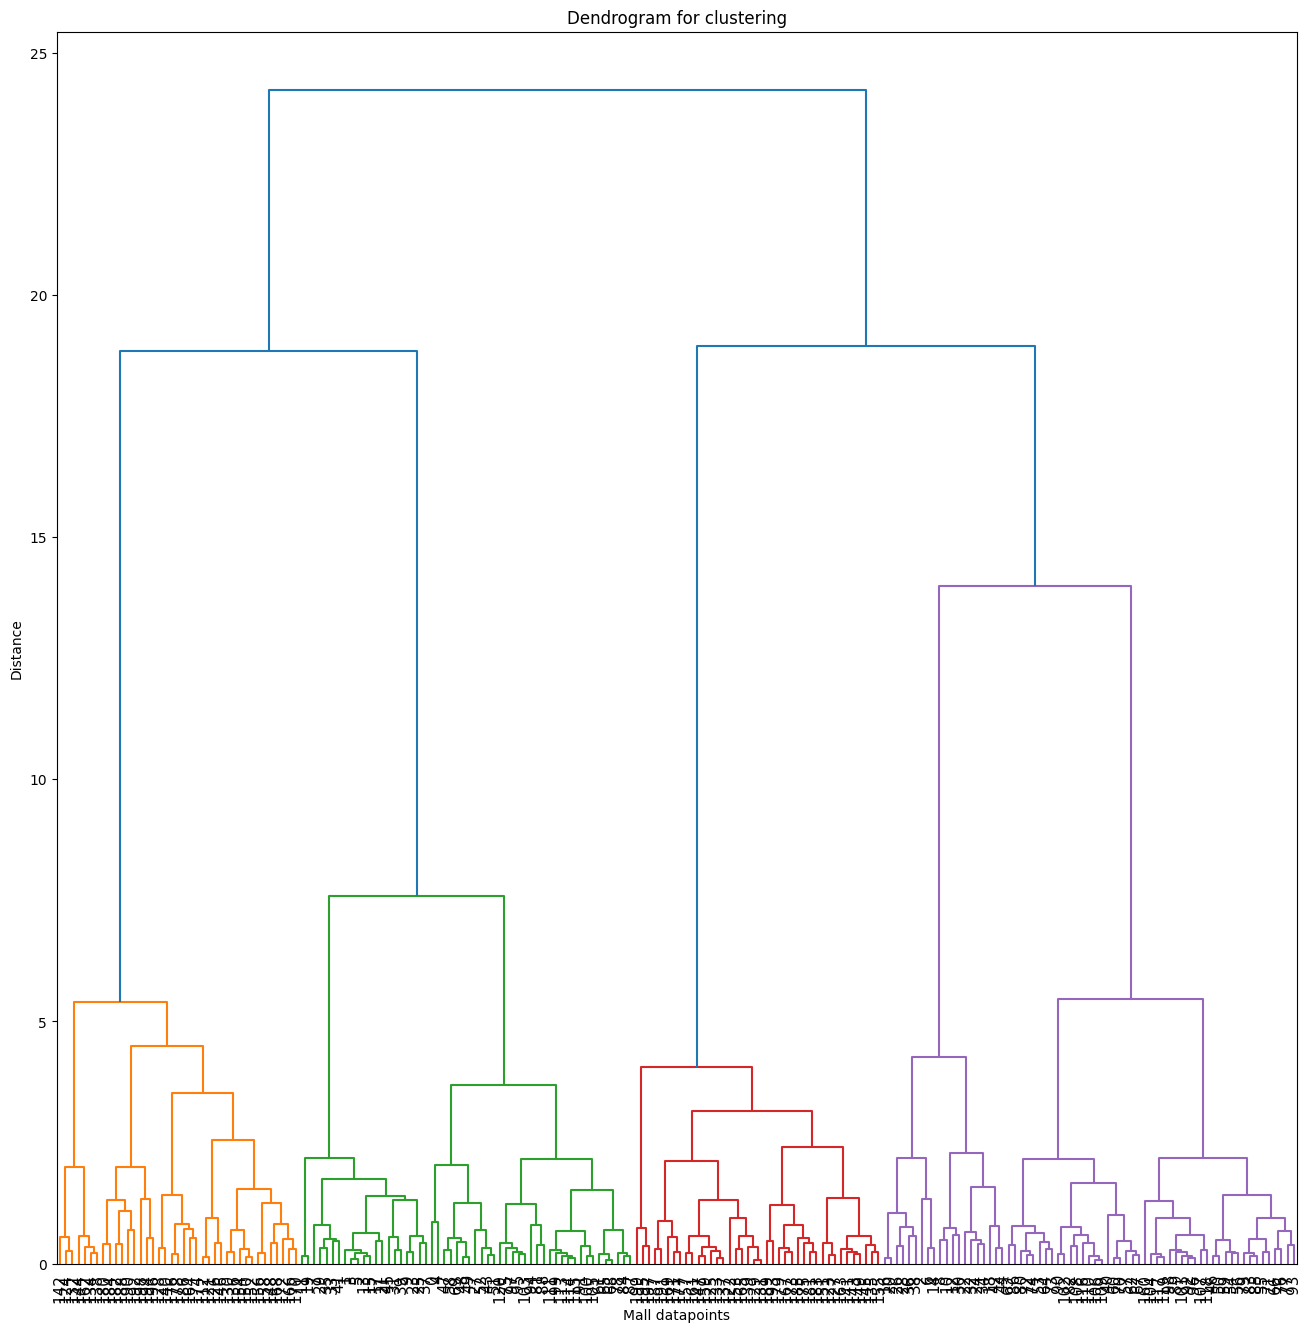

In [30]:
# Plot dendrogram

plt.figure(figsize=(16,16))
dendrogram(linkage_matrix,labels=range(len(feature_sel)), leaf_rotation=90, leaf_font_size=11)
plt.title("Dendrogram for clustering")
plt.xlabel("Mall datapoints")
plt.ylabel("Distance")
plt.show()


##``` Apply Agglomerative Hierarchical Clustering ```



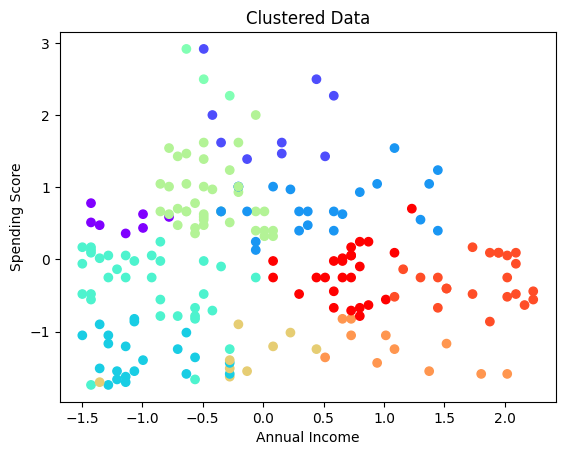

In [31]:
from scipy.cluster.hierarchy import fcluster

hierarchy_labels = fcluster(linkage_matrix, t=4, criterion='distance')

# and visualize clusters

plt.scatter(
    feature_sel.iloc[:, 0],
    feature_sel.iloc[:, 1],
    c=hierarchy_labels,
    cmap='rainbow'
)

plt.title("Clustered Data")
plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.show()

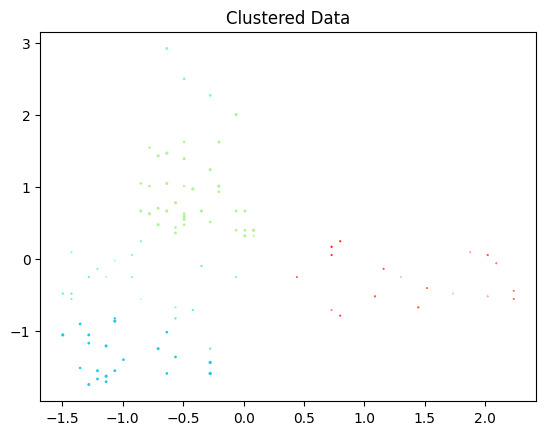

In [32]:
# for three features
plt.scatter(
    feature_sel.iloc[:, 0],
    feature_sel.iloc[:, 1],
    feature_sel.iloc[:, 2],
    c=hierarchy_labels,
    cmap='rainbow'
)

plt.title("Clustered Data")
plt.show()


##``` Compare cluster formation with K-Means ```




In [33]:
# comparing the kmeans and agglomerative hierchy clustering

from sklearn.metrics import silhouette_score
results = []

for name, cluster_labels in [
  ("K-Means", final_kmeans_label),
  ("Hierarchical", hierarchy_labels)]:

    results.append({
        "Model": name,
        "Number of Clusters": len(set(cluster_labels)),
        "Silhouette Score": silhouette_score(feature_sel, cluster_labels),
    })

comparison = pd.DataFrame(results)
comparison.round(2)

,Model,Number of Clusters,Silhouette Score
0,K-Means,5,0.56
1,Hierarchical,11,0.42


## **Task 4 – DBSCAN Clustering**

>**● Apply DBSCAN clustering**

>**● Identify clusters and noise points**

>**● Compare DBSCAN results with K-Means and Hierarchical Clustering**



## ``` Apply DBSCAN clustering ```

## ``` Identify clusters and noise points ```





In [34]:
# import first

from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=1.5, min_samples=5)
dbscan_labels = dbscan.fit(feature_sel)

In [35]:
dbscan_labels = dbscan.labels_
print(set(dbscan_labels))

{np.int64(0), np.int64(1)}


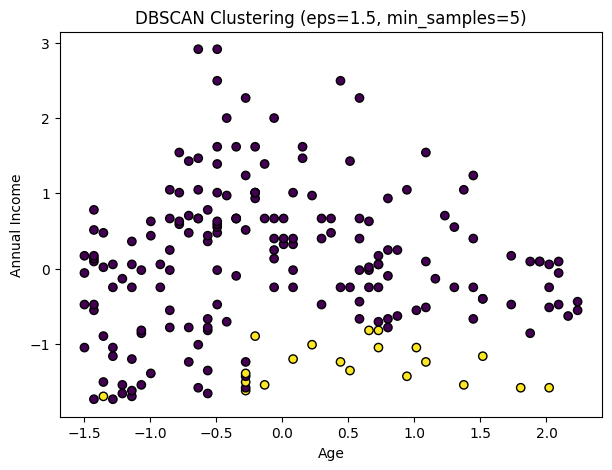

In [36]:
# visualize the dbscan plot

plt.figure(figsize=(7, 5))

plt.scatter(
    feature_sel.iloc[:, 0],
    feature_sel.iloc[:, 1],
    c=dbscan_labels,
    cmap='viridis',
    edgecolors='k'
)

plt.xlabel(feature_sel.columns[0])
plt.ylabel(feature_sel.columns[1])
plt.title("DBSCAN Clustering (eps=1.5, min_samples=5)")
plt.show()

## `Compare DBSCAN results with K-Means and Hierarchical Clustering`

In [37]:
# compare by silhouette score:

# comparing the kmeans, agglomerative hierchy clustering and DBSCAN

results = []

for name, cluster_labels in [
  ("K-Means", final_kmeans_label),
  ("Hierarchical", hierarchy_labels),
  ("DBSCAN", dbscan_labels)
  ]:

    results.append({
        "Model": name,
        "Number of Clusters": len(set(cluster_labels)),
        "Silhouette Score": silhouette_score(feature_sel, cluster_labels),
    })

comparison = pd.DataFrame(results)
comparison.round(2)

,Model,Number of Clusters,Silhouette Score
0,K-Means,5,0.56
1,Hierarchical,11,0.42
2,DBSCAN,2,0.35


## **Task 5 – Dimensionality Reduction**
>**● Apply PCA to reduce dimensionality**

>**● Apply t-SNE for low-dimensional representation**

>**● Compare insights obtained from PCA and t-SNE**



##``` Apply PCA to reduce dimensionality ```


In [38]:
# import PCA()

from sklearn.decomposition import PCA

pca = PCA()
pca.fit(feature_sel) # that feature are already scaled

PCA()

In [39]:
# Cumulative explained variance
cumulative_variance=np.cumsum(pca.explained_variance_ratio_)
cumulative_variance

array([0.39602553, 0.68521235, 0.89263989, 1.        ])

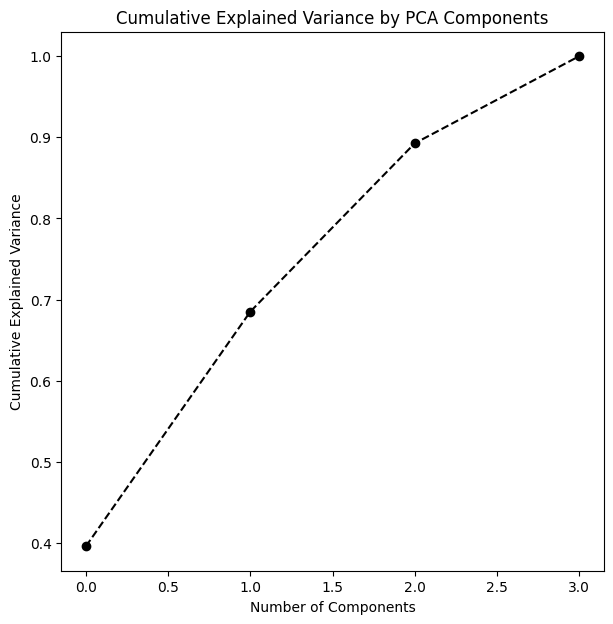

In [40]:
from matplotlib.lines import lineStyles
# visualize the plot of cummulation

plt.figure(figsize=(7,7))
plt.plot(cumulative_variance, marker='o', linestyle='--',color='black')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.show()

In [41]:
# Find the number of components to explain 95% of variance
n_components=np.argmax(cumulative_variance>=0.95)+1
n_components

np.int64(4)

In [42]:
# Fit PCA with selected number of components
pca=PCA(n_components=n_components)
feature_sel_pca=pca.fit_transform(feature_sel)

print(f"Original shape: {feature_sel.shape}")
print(f"PCA Reduced features: {feature_sel_pca.shape}")

Original shape: (200, 4)
PCA Reduced features: (200, 4)


##``` Apply t-SNE for low-dimensional representation ```

In [43]:
# import t-sne

from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=30, random_state=42,init="pca", n_iter=1000)
feature_sel_tsne = tsne.fit_transform(feature_sel)

print(f"Original feature size: {feature_sel.shape[1]}")
print(f"t-SNE projected shape: {feature_sel_tsne.shape}")

Original feature size: 4
t-SNE projected shape: (200, 2)


## `Compare insights obtained from PCA and t-SNE`

In [44]:
# Comparison between PCA and T-SNE

print(f"PCA Reduced features: {feature_sel_pca.shape}")
print(f"t-SNE projected shape: {feature_sel_tsne.shape}")

PCA Reduced features: (200, 4)
t-SNE projected shape: (200, 2)


## **Task 6 – Cluster Analysis**

>**● Analyze customer characteristics within each cluster**

>**● Identify meaningful customer segments**

>**● Provide business recommendations based on the clusters**

**The customers were grouped into different clusters based on their spending patterns and other selected features. Each cluster represents a group of customers with similar characteristics. These segments can help the mall understand customer behaviour and identify potential high-value customers.**

**Business Recommendations:**

- Provide loyalty rewards to high-spending customers.
- Offer discounts and promotions to encourage more purchases.
- Use targeted marketing strategies for different customer segments.

**Conclusion:**

> Customer clustering helps the mall understand customer behaviour, improve customer satisfaction, and develop effective marketing strategies to increase sales.

